# Разработка A/B-тестирования и анализ результатов

**Автор проекта: Наместникова Соня**

Вы работаете продуктовым аналитиком в компании, которая разрабатывает развлекательное приложение с функцией «бесконечной» ленты, как, например, в приложениях с короткими видео. В вашем приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Вас, как аналитика, просят помочь рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.


## Описание данных

Вы будете работать с тремя таблицами:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-11 по 2025-09-23. Путь к файлу: `/datasets/sessions_project_history.csv`.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. Путь к файлу: `/datasets/sessions_project_test_part.csv`.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. Путь к файлу: `/datasets/sessions_project_test.csv`.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).


## Что нужно сделать
Ваши задачи: рассчитать параметры теста, оценить корректность его проведения и проанализировать результаты эксперимента.

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных
На первом этапе поработайте с историческими данными приложения:

- Импортируйте библиотеку pandas.

- Считайте и сохраните в датафрейм `sessions_history` CSV-файл с историческими данными о сессиях пользователей `sessions_project_history.csv`.

Выведите на экран первые пять строк полученного датафрейма.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from math import ceil
from scipy.stats import ttest_ind
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

In [2]:
sessions_history = pd.read_csv(
    'https://code.s3.yandex.net/datasets/sessions_project_history.csv'
)

date_columns = ['session_date', 'session_start_ts', 'install_date']
sessions_history[date_columns] = sessions_history[date_columns].apply(pd.to_datetime)

In [3]:
display(sessions_history.head())
sessions_history.info()

print('Количество пропусков:')
display(sessions_history.isna().sum())
print('Количество явных дубликатов:', sessions_history.duplicated().sum())
print(
    'Период наблюдения:',
    sessions_history['session_date'].min().date(),
    '-',
    sessions_history['session_date'].max().date()
)


,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


<class 'pandas.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   user_id            435924 non-null  str           
 1   session_id         435924 non-null  str           
 2   session_date       435924 non-null  datetime64[us]
 3   session_start_ts   435924 non-null  datetime64[us]
 4   install_date       435924 non-null  datetime64[us]
 5   session_number     435924 non-null  int64         
 6   registration_flag  435924 non-null  int64         
 7   page_counter       435924 non-null  int64         
 8   region             435924 non-null  str           
 9   device             435924 non-null  str           
dtypes: datetime64[us](3), int64(3), str(4)
memory usage: 33.3 MB
Количество пропусков:


user_id              0
session_id           0
session_date         0
session_start_ts     0
install_date         0
session_number       0
registration_flag    0
page_counter         0
region               0
device               0
dtype: int64

Количество явных дубликатов: 0
Период наблюдения: 2025-08-11 - 2025-09-23


**Вывод:** в таблице 435 924 строки и 10 столбцов. Данные охватывают 44 дня, с 11 августа по 23 сентября 2025 года. Пропусков и явных дубликатов нет. После преобразования дат типы данных соответствуют содержанию столбцов.

#### 1.2. Знакомство с данными
- Для каждого уникального пользователя `user_id` рассчитайте количество уникальных сессий `session_id`.

- Выведите на экран все данные из таблицы `sessions_history` для одного пользователя с наибольшим количеством сессий. Если таких пользователей несколько, выберите любого из них.

- Изучите таблицу для одного пользователя, чтобы лучше понять логику формирования каждого столбца данных.



In [4]:
sessions_count = (
    sessions_history.groupby('user_id', as_index=False)
    .agg(sessions_count=('session_id', 'nunique'))
)

display(sessions_count.head())

,user_id,sessions_count
0,00005FB6A13A6FBE,2
1,0000B15A18D77ED9,3
2,0000C4E3A4A571A9,2
3,000293FAF9E67A81,4
4,00029C5AE889A6C3,2


In [5]:
max_count_uid = sessions_count.loc[
    sessions_count['sessions_count'].idxmax(),
    'user_id'
]

print('Пользователь с наибольшим числом сессий:', max_count_uid)
print('Количество его сессий:', sessions_count['sessions_count'].max())

Пользователь с наибольшим числом сессий: 10E0DEFC1ABDBBE0
Количество его сессий: 10


In [6]:
sessions_history[sessions_history['user_id'] == max_count_uid].sort_values(
    'session_start_ts'
)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


**Вывод:** в данных 134 039 уникальных пользователей и 435 924 уникальные сессии. На одного пользователя приходится от 1 до 10 сессий, медиана равна 3. У пользователя с максимальным числом наблюдений сессии идут в хронологическом порядке, `session_number` обозначает их порядковый номер, а одна строка соответствует одной сессии.

#### 1.3. Анализ числа регистраций
Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируйте, как менялось число регистраций в приложении за время его существования.

- Агрегируйте исторические данные и рассчитайте число уникальных пользователей и число зарегистрированных пользователей для каждого дня наблюдения. Для простоты считайте, что у пользователя в течение дня бывает одна сессия максимум и статус регистрации в течение одного дня не может измениться.

- Постройте линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням. Отобразите их на одном графике.

- Постройте отдельный линейный график доли зарегистрированных пользователей от всех пользователей по дням.

- На обоих графиках должны быть заголовок, подписанные оси X и Y, сетка и легенда.

In [7]:
daily_users = (
    sessions_history.groupby('session_date', as_index=False)
    .agg(total_users=('user_id', 'nunique'))
)

daily_registered = (
    sessions_history[sessions_history['registration_flag'] == 1]
    .groupby('session_date', as_index=False)
    .agg(registered_users=('user_id', 'nunique'))
)

data = daily_users.merge(daily_registered, on='session_date', how='left')
data['registered_users'] = data['registered_users'].fillna(0).astype(int)
data['registered_share'] = data['registered_users'] / data['total_users']

display(data.head())

,session_date,total_users,registered_users,registered_share
0,2025-08-11,3919,169,0.043123
1,2025-08-12,6056,336,0.055482
2,2025-08-13,8489,464,0.054659
3,2025-08-14,10321,625,0.060556
4,2025-08-15,14065,840,0.059723


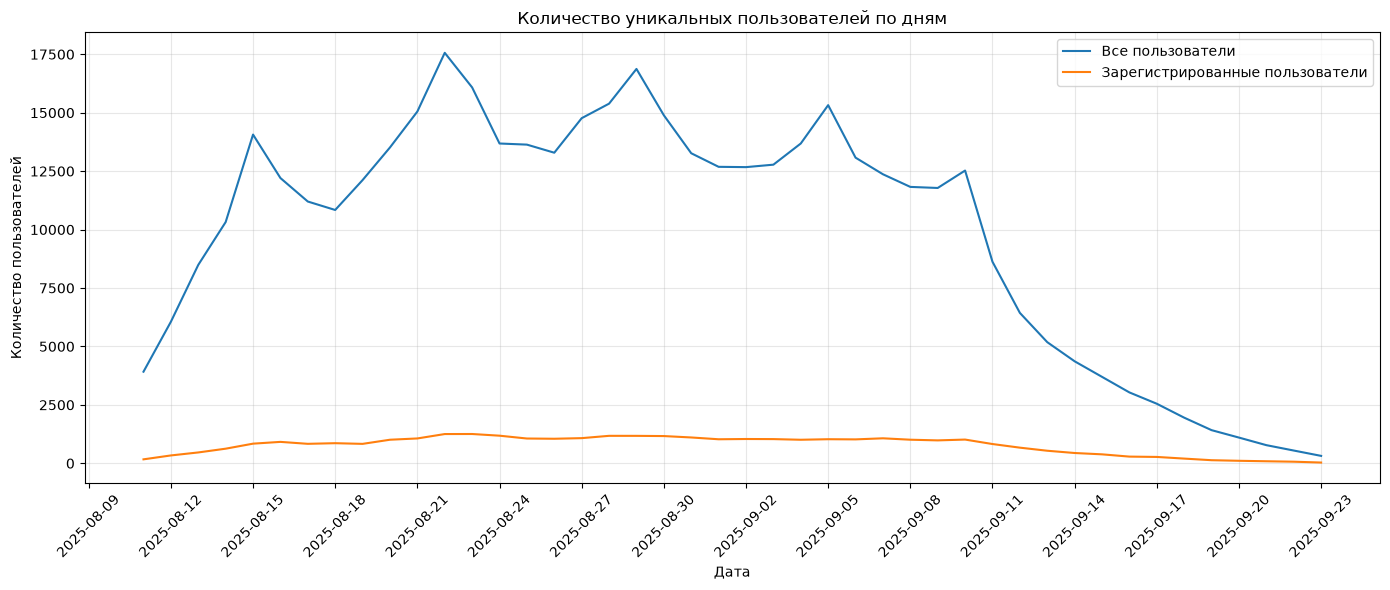

In [8]:
plt.figure(figsize=(14, 6))
plt.plot(data['session_date'], data['total_users'], label='Все пользователи')
plt.plot(
    data['session_date'],
    data['registered_users'],
    label='Зарегистрированные пользователи'
)

plt.title('Количество уникальных пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Количество пользователей')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Вывод:** за период наблюдения дневной трафик заметно менялся: число уникальных пользователей составляло от 317 до 17 563. Число зарегистрированных пользователей менялось вместе с общим трафиком и составляло от 32 до 1 253 в день. В конце периода количество наблюдений резко снижается, поэтому средний дневной трафик нужно использовать как приблизительную оценку.

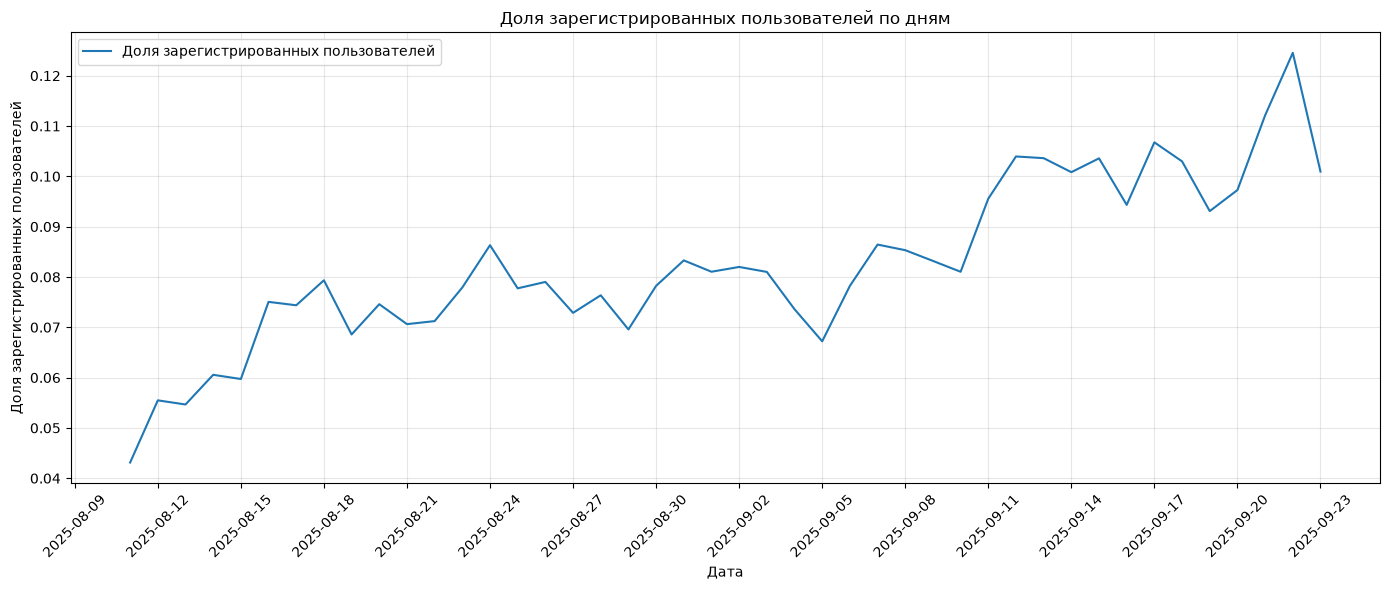

In [9]:
plt.figure(figsize=(14, 6))
plt.plot(
    data['session_date'],
    data['registered_share'],
    label='Доля зарегистрированных пользователей'
)

plt.title('Доля зарегистрированных пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Доля зарегистрированных пользователей')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Вывод:** в начале периода доля зарегистрированных пользователей составляла 4,3%, затем в целом росла. Максимум 12,5% был зафиксирован 22 сентября. В последний день доля составила 10,1%. На последних датах пользователей мало, поэтому дневные значения сильнее колеблются.

#### 1.4. Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

- Найдите количество сессий для каждого значения количества просмотренных страниц. Например: одну страницу просмотрели в 29 160 сессиях, две страницы — в 105 536 сессиях и так далее.

- Постройте столбчатую диаграмму, где по оси X будет число просмотренных страниц, по оси Y — количество сессий.

- На диаграмме должны быть заголовок, подписанные оси X и Y.

In [10]:
page_count_df = (
    sessions_history.groupby('page_counter', as_index=False)
    .agg(sessions_count=('session_id', 'nunique'))
)

display(page_count_df)

,page_counter,sessions_count
0,1,29160
1,2,105536
2,3,166690
3,4,105569
4,5,26288
5,6,2589
6,7,92


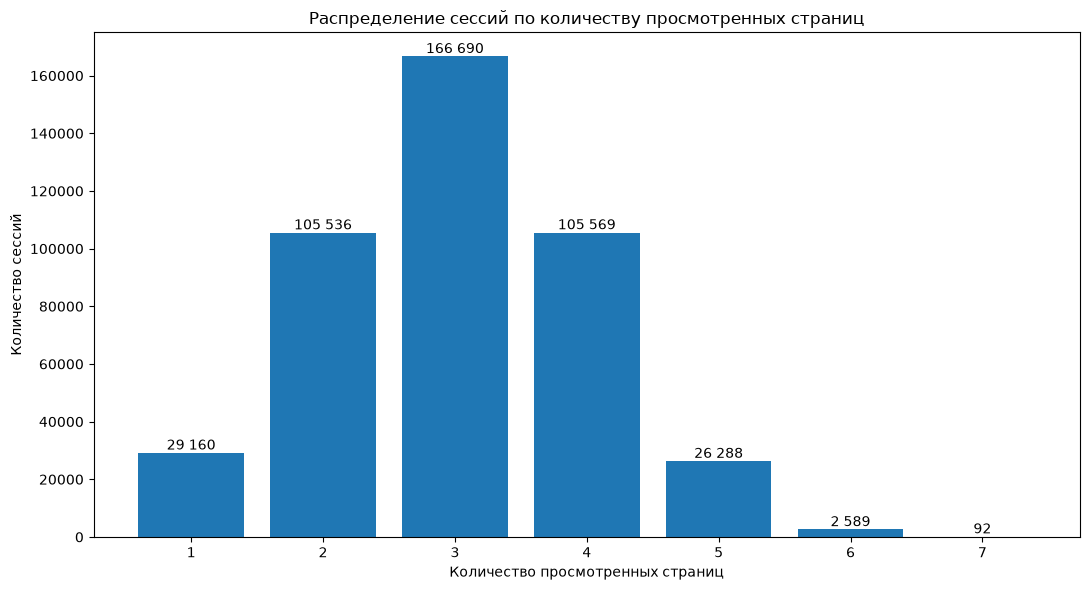

In [11]:
plt.figure(figsize=(11, 6))
plt.bar(page_count_df['page_counter'], page_count_df['sessions_count'])
plt.title('Распределение сессий по количеству просмотренных страниц')
plt.xlabel('Количество просмотренных страниц')
plt.ylabel('Количество сессий')

for pages, sessions in zip(
    page_count_df['page_counter'],
    page_count_df['sessions_count']
):
    plt.text(pages, sessions, f'{sessions:,}'.replace(',', ' '), ha='center', va='bottom')

plt.tight_layout()
plt.show()

**Вывод:** чаще всего за сессию пользователи просматривали 3 страницы, таких сессий было 166 690. Основная часть наблюдений приходится на 2-4 страницы. Сессии с 6 и 7 страницами встречались редко.

#### 1.5. Доля пользователей, просмотревших более четырёх страниц
Продуктовая команда продукта считает, что сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.

- В датафрейме `sessions_history` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше.

- Постройте график со средним значением доли успешных сессий от всех сессий по дням за весь период наблюдения.

In [12]:
sessions_history['good_session'] = (
    sessions_history['page_counter'].ge(4).astype(int)
)

sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,good_session
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone,0
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android,1
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC,1
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android,1
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android,0


In [13]:
first_sessions = sessions_history.query('session_number == 1').copy()

good_sessions_df = (
    first_sessions.groupby('session_date', as_index=False)
    .agg(
        good_sessions=('good_session', 'sum'),
        total_sessions=('session_id', 'nunique')
    )
)

good_sessions_df['good_session_share'] = (
    good_sessions_df['good_sessions'] / good_sessions_df['total_sessions']
)

display(good_sessions_df.head())

,session_date,good_sessions,total_sessions,good_session_share
0,2025-08-11,1226,3919,0.312835
1,2025-08-12,1225,4106,0.298344
2,2025-08-13,1561,5087,0.306861
3,2025-08-14,1741,5456,0.319098
4,2025-08-15,2427,7801,0.311114


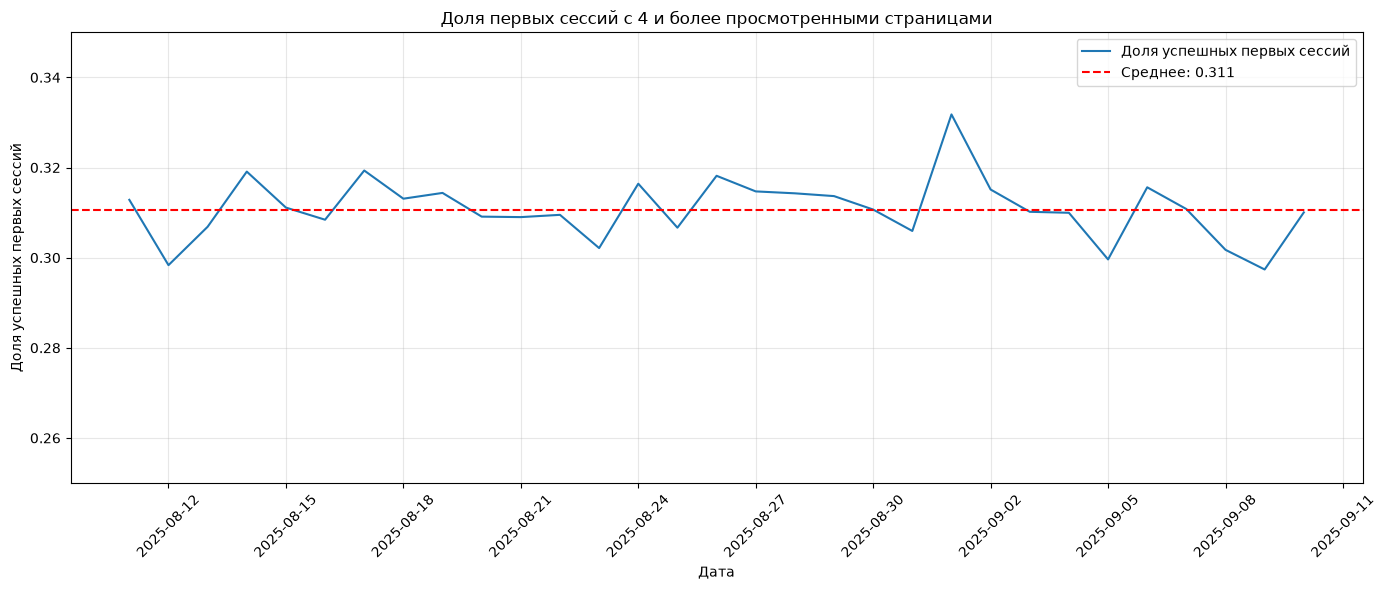

Средняя доля успешных первых сессий: 31.06%


In [14]:
mean_good_session_share = (
    sessions_history.query('session_number == 1')['good_session'].mean()
)

plt.figure(figsize=(14, 6))
plt.plot(
    good_sessions_df['session_date'],
    good_sessions_df['good_session_share'],
    label='Доля успешных первых сессий'
)
plt.axhline(
    mean_good_session_share,
    color='red',
    linestyle='--',
    label=f'Среднее: {mean_good_session_share:.3f}'
)

plt.title('Доля первых сессий с 4 и более просмотренными страницами')
plt.xlabel('Дата')
plt.ylabel('Доля успешных первых сессий')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.xticks(rotation=45)
plt.ylim(0.25, 0.35)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f'Средняя доля успешных первых сессий: {mean_good_session_share:.2%}')

**Вывод:** среди первых сессий успешными были 31,06%. По дням доля менялась примерно от 29,7% до 33,2%, поэтому показатель можно использовать как базовый для расчёта выборки.

**Промежуточный вывод:** в исторических данных 435 924 сессии и 134 039 пользователей. Пропусков и явных дубликатов нет. Чаще всего пользователи просматривали 3 страницы за сессию. Среди первых сессий успешными, то есть с 4 и более страницами, были 31,06%. Эта доля будет базовой для планирования A/B-теста.

### 2. Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Сформулировать нулевую и альтернативную гипотезы

- Определиться с целевой метрикой.

- Рассчитать необходимый размер выборки.

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### 2.1 Формулировка нулевой и альтернативной гипотез

Перед тем как проводить А/B-тест, необходимо сформулировать нулевую и альтернативную гипотезы. Напомним изначальное условие: команда разработчиков рекомендательных систем создала новый алгоритм, который, по их мнению, будет показывать более интересный контент для каждого пользователя.

О какой метрике идёт речь? Как она будет учтена в формулировке гипотез?

Целевой метрикой я выбрала долю успешных сессий, то есть сессий, в которых пользователь просмотрел 4 страницы или больше. Такая метрика показывает, насколько пользователям интересны рекомендации. Её базовое значение можно рассчитать по историческим данным.

Сформулирую односторонние гипотезы:

**H0:** доля успешных сессий в группе B с новым алгоритмом равна доле успешных сессий в группе A с прежним алгоритмом, `pB = pA`.

**H1:** доля успешных сессий в группе B с новым алгоритмом выше, чем в группе A, `pB > pA`.


#### 2.2. Расчёт размера выборки
В рамках курса вы уже рассчитывали размеры выборки и  использовали для этого онлайн-калькулятор. В этом задании предлагаем воспользоваться готовым кодом и рассчитать необходимое для вашего эксперимента количество пользователей.

Для этого установите в коде ниже следующие параметры:

- Уровень значимости — 0.05.

- Вероятность ошибки второго рода — 0.2.

- Мощность теста.

- Минимальный детектируемый эффект, или MDE, — 3%. Обратите внимание, что здесь нужно указать десятичную дробь, а не процент.

При расчёте размера выборки используйте метод `solve_power()` из класса `power.NormalIndPower` модуля `statsmodels.stats`.

Запустите ячейку и изучите полученное значение.

In [15]:
# Параметры теста
alpha = 0.05
beta = 0.2
power = 1 - beta

# Для расчёта по условию используем базовую долю 30%
p = 0.3
mde = 0.03
p2 = p * (1 + mde)
effect_size = abs(proportion_effectsize(p, p2))

power_analysis = NormalIndPower()
sample_size = power_analysis.solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1
)
sample_size_per_group = ceil(sample_size)

print(f'Базовая доля: {p:.2%}')
print(f'Ожидаемая доля после роста на 3%: {p2:.2%}')
print(f'Относительный MDE: {mde:.0%}')
print(f'Расчётный размер выборки: {sample_size:.2f}')
print(f'Размер выборки после округления вверх: {sample_size_per_group}')

Базовая доля: 30.00%
Ожидаемая доля после роста на 3%: 30.90%
Относительный MDE: 3%
Расчётный размер выборки: 41040.69
Размер выборки после округления вверх: 41041


**Вывод:** при базовой доле 30%, относительном MDE 3%, уровне значимости 5% и мощности 80% расчёт даёт около 41 040 пользователей на группу. После округления вверх нужно взять 41 041 пользователя.

#### 2.3. Расчёт длительности A/B-теста

Используйте данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения. Рассчитайте длительность теста, разделив одно на другое.

- Рассчитайте среднее количество уникальных пользователей приложения в день.

- Определите длительность теста исходя из рассчитанного значения размера выборок и среднего дневного трафика приложения. Количество дней округлите в большую сторону.

In [16]:
avg_daily_users = (
    sessions_history.groupby('session_date')['user_id']
    .nunique()
    .mean()
)

total_sample_size = sample_size_per_group * 2
test_duration = ceil(total_sample_size / avg_daily_users)

print(f'Среднее число уникальных пользователей в день: {avg_daily_users:.0f}')
print(f'Общий необходимый размер выборки: {total_sample_size}')
print(f'Расчётная длительность теста: {test_duration} дней')

Среднее число уникальных пользователей в день: 9907
Общий необходимый размер выборки: 82082
Расчётная длительность теста: 9 дней


**Вывод:** приложение посещали в среднем около 9 907 уникальных пользователей в день. Чтобы набрать 82 082 пользователя в две группы, потребуется 9 дней.

### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

A/B-тест успешно запущен, и уже доступны данные за первые три дня. На этом этапе нужно убедиться, что всё идёт хорошо: пользователи разделены правильным образом, а интересующие вас метрики корректно считаются.

- Считайте и сохраните в датафрейм `sessions_test_part` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test_part.csv`.

- Рассчитайте количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения.

- Рассчитайте и выведите на экран процентную разницу в количестве пользователей в группах A и B. Постройте любую удобную визуализацию, на которой будет видно возможное различие двух групп.

Для расчёта процентной разницы воспользуйтесь формулой:
$$P = 100 \cdot  \frac{|A − B|}{A}$$

In [17]:
sessions_test_part = pd.read_csv(
    'https://code.s3.yandex.net/datasets/sessions_project_test_part.csv'
)
sessions_test_part[date_columns] = sessions_test_part[date_columns].apply(pd.to_datetime)

display(sessions_test_part.head())
print(
    'Период данных:',
    sessions_test_part['session_date'].min().date(),
    '-',
    sessions_test_part['session_date'].max().date()
)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,3404844B53442747,B4901323BD537E45,2025-10-14,2025-10-14 19:28:49,2025-10-14,1,0,3,CIS,Android,B
1,3A2BF4D364E62D89,216FC619308F8788,2025-10-14,2025-10-14 21:11:04,2025-10-14,1,0,3,MENA,iPhone,A
2,79CDAE11E32B1597,EDFCE4AC1A504074,2025-10-14,2025-10-14 21:44:03,2025-10-14,1,0,3,CIS,iPhone,A
3,D6AF8D78297A931F,CF0AC0EEDE92C690,2025-10-14,2025-10-14 19:07:55,2025-10-14,1,0,4,CIS,PC,A
4,37E0CE723AE568E0,2E6ED45E8C86C4E9,2025-10-14,2025-10-14 15:39:44,2025-10-14,1,0,3,CIS,Mac,B


Период данных: 2025-10-14 - 2025-10-14


In [18]:
users_by_group = (
    sessions_test_part.groupby('test_group')['user_id']
    .nunique()
    .sort_index()
)

a_users = users_by_group['A']
b_users = users_by_group['B']
display(users_by_group)

test_group
A    1477
B    1466
Name: user_id, dtype: int64

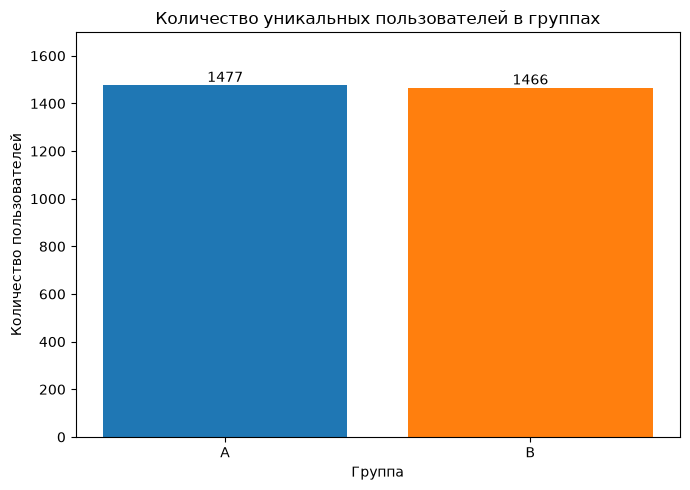

Процентная разница между группами: 0.74%


In [19]:
percentage_difference = 100 * abs(a_users - b_users) / a_users

plt.figure(figsize=(7, 5))
bars = plt.bar(users_by_group.index, users_by_group.values, color=['C0', 'C1'])
plt.title('Количество уникальных пользователей в группах')
plt.xlabel('Группа')
plt.ylabel('Количество пользователей')
plt.bar_label(bars)
plt.ylim(0, users_by_group.max() * 1.15)
plt.tight_layout()
plt.show()

print(f'Процентная разница между группами: {percentage_difference:.2f}%')

#### 3.2. Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

- Рассчитайте количество пользователей, которые встречаются одновременно в группах A и B, или убедитесь, что таких нет.

In [20]:
users_a = set(sessions_test_part.loc[
    sessions_test_part['test_group'] == 'A',
    'user_id'
])
users_b = set(sessions_test_part.loc[
    sessions_test_part['test_group'] == 'B',
    'user_id'
])

intersection = users_a.intersection(users_b)
print('Количество пользователей в обеих группах:', len(intersection))

Количество пользователей в обеих группах: 0


**Вывод:** в группе A было 1 477 уникальных пользователей, в группе B 1 466. Разница составила 0,74%, поэтому по размеру группы сопоставимы. Пересечений между группами нет, условие независимости соблюдено.

#### 3.3. Равномерность разделения пользователей по устройствам
Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

Постройте две диаграммы:

- доля каждого типа устройства для пользователей из группы A,

- доля каждого типа устройства для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение устройств в группах A и B.


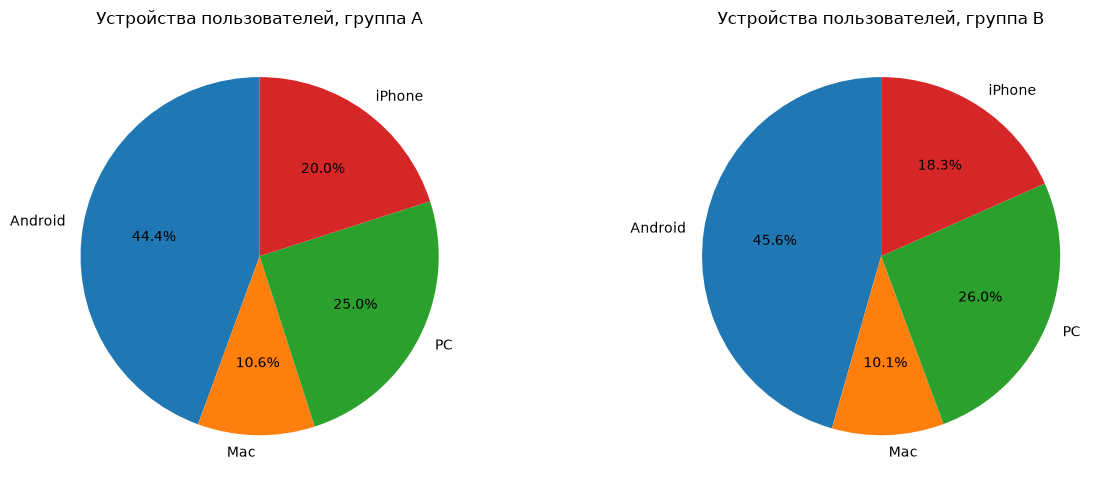

device,Android,Mac,PC,iPhone
test_group,,,,
A,44.41,10.56,24.98,20.04
B,45.57,10.10,25.99,18.35


In [21]:
user_devices = sessions_test_part.drop_duplicates('user_id')
device_share = pd.crosstab(
    user_devices['test_group'],
    user_devices['device'],
    normalize='index'
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, group in zip(axes, ['A', 'B']):
    axis.pie(
        device_share.loc[group],
        labels=device_share.columns,
        autopct='%.1f%%',
        startangle=90
    )
    axis.set_title(f'Устройства пользователей, группа {group}')

plt.tight_layout()
plt.show()

display((device_share * 100).round(2))

#### 3.4. Равномерность распределения пользователей по регионам
Теперь убедитесь, что пользователи равномерно распределены по регионам.

Постройте две диаграммы:

- доля каждого региона для пользователей из группы A,

- доля каждого региона для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение регионов в группах A и B. Постарайтесь использовать другой тип диаграммы, не тот, что в прошлом задании.


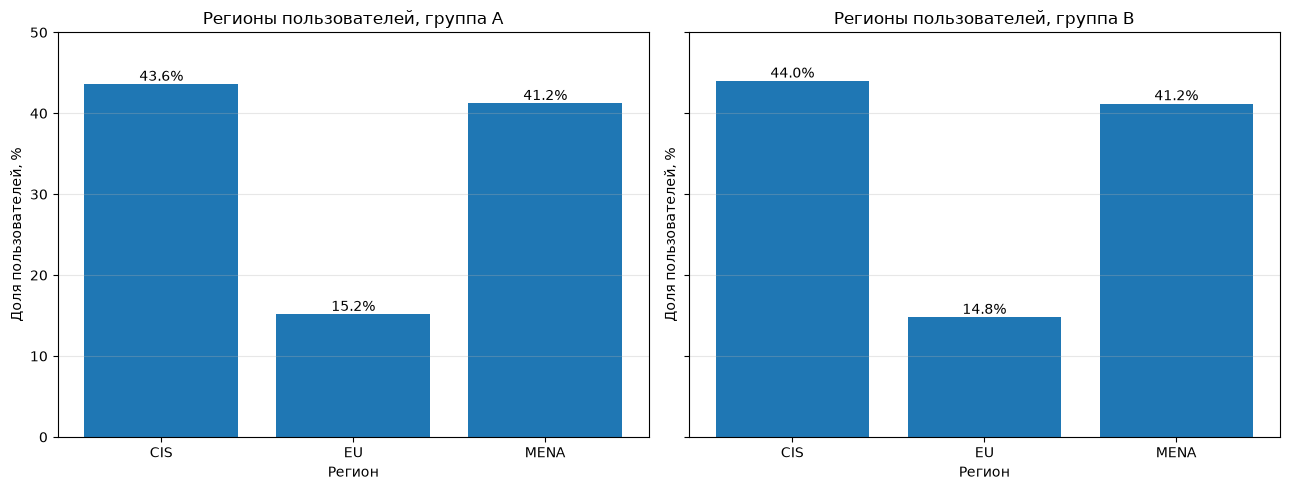

region,CIS,EU,MENA
test_group,,,
A,43.6,15.17,41.23
B,44.0,14.80,41.20


In [22]:
user_regions = sessions_test_part.drop_duplicates('user_id')
region_share = pd.crosstab(
    user_regions['test_group'],
    user_regions['region'],
    normalize='index'
) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for axis, group in zip(axes, ['A', 'B']):
    bars = axis.bar(region_share.columns, region_share.loc[group])
    axis.set_title(f'Регионы пользователей, группа {group}')
    axis.set_xlabel('Регион')
    axis.set_ylabel('Доля пользователей, %')
    axis.bar_label(bars, fmt='%.1f%%')
    axis.set_ylim(0, 50)
    axis.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

display(region_share.round(2))

**Вывод:** распределения по устройствам и регионам почти одинаковые. Максимальная разница между группами по устройствам составляет 1,69 процентного пункта, по регионам 0,40 процентного пункта. Существенного перекоса между группами нет.

#### 3.5. Вывод после проверки A/B-теста

На основе проведённого анализа A/B-теста сформулируйте и запишите свои выводы. В выводе обязательно укажите:

- Было ли обнаружено различие в количестве пользователей в двух группах.

- Являются ли выборки независимыми. Было ли обнаружено пересечение пользователей из тестовой и контрольной групп.

- Сохраняется ли равномерное распределение пользователей тестовой и контрольной групп по категориальным переменным: устройствам и регионам.

Сделайте заключение: корректно ли проходит A/B-тест, или наблюдаются какие-либо нарушения.

По итогам первого дня тест идёт корректно:

* в группе A 1 477 пользователей, в группе B 1 466, разница составляет 0,74%;
* один и тот же пользователь не встречается в обеих группах;
* распределения по устройствам и регионам почти одинаковые.

Нарушений в распределении пользователей не видно, поэтому тест можно продолжать.


### 4. Проверка результатов A/B-теста

A/B-тест завершён, и у вас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### 4.1. Получение результатов теста и подсчёт основной метрики

- Считайте и сохраните в датафрейм `sessions_test` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test.csv`.

- В датафрейме `sessions_test` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если просмотрено меньше.

In [23]:
sessions_test = pd.read_csv(
    'https://code.s3.yandex.net/datasets/sessions_project_test.csv'
)
sessions_test[date_columns] = sessions_test[date_columns].apply(pd.to_datetime)
sessions_test['good_session'] = sessions_test['page_counter'].ge(4).astype(int)

display(sessions_test.head())
print('Количество пропусков:', sessions_test.isna().sum().sum())
print('Количество явных дубликатов:', sessions_test.duplicated().sum())

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A,0
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B,0
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A,0
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B,0
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0


Количество пропусков: 0
Количество явных дубликатов: 0


#### 4.2. Проверка корректности результатов теста

Прежде чем приступать к анализу ключевых продуктовых метрик, необходимо убедиться, что тест проведён корректно и вы будете сравнивать две сопоставимые группы.

- Рассчитайте количество уникальных сессий для каждого дня и обеих тестовых групп, используя группировку.

- Проверьте, что количество уникальных дневных сессий в двух выборках не различается или различия не статистически значимыми. Используйте статистический тест, который позволит сделать вывод о равенстве средних двух выборок.

- В качестве ответа выведите на экран полученное значение p-value и интерпретируйте его.

In [24]:
daily_sessions_count = (
    sessions_test.groupby(['session_date', 'test_group'])['session_id']
    .nunique()
    .unstack('test_group')
)

display(daily_sessions_count.head())

test_group,A,B
session_date,,
2025-10-14,1502,1628
2025-10-15,2235,2283
2025-10-16,3280,3241
2025-10-17,4089,4054
2025-10-18,5013,5059


In [25]:
test_users_by_group = (
    sessions_test.groupby('test_group')['user_id']
    .nunique()
)

print('Количество уникальных пользователей:')
display(test_users_by_group)
print('Количество пользователей в обеих группах:', sessions_test.groupby('user_id')['test_group'].nunique().gt(1).sum())

Количество уникальных пользователей:


test_group
A    15163
B    15416
Name: user_id, dtype: int64

Количество пользователей в обеих группах: 0


Проверяемые гипотезы:

* **H0:** среднее число уникальных дневных сессий одинаково в группах A и B.
* **H1:** среднее число уникальных дневных сессий различается между группами A и B.

Для проверки использую двусторонний t-тест для независимых выборок с уровнем значимости 0,05.

In [26]:
alpha = 0.05
sessions_balance_test = ttest_ind(
    daily_sessions_count['A'],
    daily_sessions_count['B'],
    alternative='two-sided'
)

print(f"Среднее число дневных сессий в группе A: {daily_sessions_count['A'].mean():.2f}")
print(f"Среднее число дневных сессий в группе B: {daily_sessions_count['B'].mean():.2f}")
print(f'p-value: {sessions_balance_test.pvalue:.6f}')

if sessions_balance_test.pvalue < alpha:
    print('Отвергаю H0: число дневных сессий в группах различается статистически значимо.')
else:
    print('Не отвергаю H0: статистически значимого различия не обнаружено.')

Среднее число дневных сессий в группе A: 2477.55
Среднее число дневных сессий в группе B: 2522.70
p-value: 0.938219
Не отвергаю H0: статистически значимого различия не обнаружено.


#### 4.3. Сравнение доли успешных сессий

Когда вы убедились, что количество сессий в обеих выборках не различалось, можно переходить к анализу ключевой метрики — доли успешных сессий.

Используйте созданный на первом шаге задания столбец `good_session` и рассчитайте долю успешных сессий для выборок A и B, а также разницу в этом показателе. Полученный вывод отобразите на экране.

In [27]:
group_metrics = (
    sessions_test.groupby('test_group')
    .agg(
        successful_sessions=('good_session', 'sum'),
        total_sessions=('session_id', 'nunique'),
        successful_share=('good_session', 'mean')
    )
)

a_share = group_metrics.loc['A', 'successful_share']
b_share = group_metrics.loc['B', 'successful_share']
absolute_difference = b_share - a_share
relative_difference = b_share / a_share - 1

display(group_metrics)
print(f'Доля успешных сессий в группе A: {a_share:.2%}')
print(f'Доля успешных сессий в группе B: {b_share:.2%}')
print(f'Абсолютный прирост B к A: {absolute_difference:.2%}')
print(f'Относительный прирост B к A: {relative_difference:.2%}')

,successful_sessions,total_sessions,successful_share
test_group,,,
A,15248,49551,0.307723
B,16059,50454,0.318290


Доля успешных сессий в группе A: 30.77%
Доля успешных сессий в группе B: 31.83%
Абсолютный прирост B к A: 1.06%
Относительный прирост B к A: 3.43%


#### 4.4. Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге вы убедились, что количество успешных сессий в тестовой выборке примерно на 1.1% выше, чем в контрольной, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.

- Используя статистический тест, рассчитайте, является ли изменение в метрике доли успешных сессий статистически значимым.

- Выведите на экран полученное значение p-value и свои выводы о статистической значимости. Напомним, что уровень значимости в эксперименте был выбран на уровне 0.05.

In [28]:
successful_sessions = [
    group_metrics.loc['B', 'successful_sessions'],
    group_metrics.loc['A', 'successful_sessions']
]
total_sessions = [
    group_metrics.loc['B', 'total_sessions'],
    group_metrics.loc['A', 'total_sessions']
]

z_stat, p_value = proportions_ztest(
    successful_sessions,
    total_sessions,
    alternative='larger'
)

print(f'Z-статистика: {z_stat:.4f}')
print(f'p-value: {p_value:.6f}')

if p_value < alpha:
    print('Отвергаю H0. В группе B доля успешных сессий статистически значимо выше.')
else:
    print('Не отвергаю H0. Статистически значимый рост метрики не подтверждён.')

Z-статистика: 3.6027
p-value: 0.000157
Отвергаю H0. В группе B доля успешных сессий статистически значимо выше.


#### 4.5. Вывод по результатам A/B-эксперимента

На основе проведённого анализа результатов теста сформулируйте и запишите свои выводы для команды разработки приложения. В выводе обязательно укажите:

- Характеристики проведённого эксперимента, количество задействованных пользователей и длительность эксперимента.

- Повлияло ли внедрение нового алгоритма рекомендаций на рост ключевой метрики и как.

- Каким получилось значение p-value для оценки статистической значимости выявленного эффекта.

- Стоит ли внедрять нововведение в приложение.

### Вывод по результатам A/B-теста

Тест шёл 20 дней, с 14 октября по 2 ноября 2025 года. В нём участвовали 30 579 уникальных пользователей: 15 163 в группе A и 15 416 в группе B. Пользователи совершили 49 551 и 50 454 сессии соответственно. Пересечений между группами нет.

Среднее число сессий в день составило 2 477,55 в группе A и 2 522,70 в группе B. При проверке этого показателя p-value составил 0,938. Это больше 0,05, поэтому статистически значимой разницы нет. По количеству дневных сессий группы сопоставимы.

Доля успешных сессий составила 30,77% в группе A и 31,83% в группе B. Новый алгоритм дал прирост на 1,06 процентного пункта, или на 3,43% относительно группы A.

Для проверки основной метрики я использовала односторонний z-тест пропорций. Полученное p-value равно 0,000157, что меньше уровня значимости 0,05. Поэтому нулевую гипотезу отвергаю: в группе B доля успешных сессий статистически значимо выше.

Новый алгоритм можно внедрять постепенно. После запуска я бы продолжила следить за удержанием пользователей, оформлением подписки и рекламной выручкой, чтобы проверить влияние на другие показатели продукта.
